EXECUTIVE DECISION INTELLIGENCE DASHBOARD
Total Revenue: ₹13,730,604
Total Cost: ₹7,938,940
Total Profit: ₹5,791,664
Overall Profit Margin: 42.18%
Sales Target Achievement: 97.05%
Average Customer Satisfaction: 3.84/5
Average On-Time Delivery: 83.14%

BUSINESS UNIT PERFORMANCE
business_unit  revenue  profit  profit_margin_pct  target_achievement_pct  customer_satisfaction  on_time_delivery_pct performance_status
         West  1914414 1285049              67.12                  156.02                   2.83                 75.47             Strong
          SME  1499890 1015111              67.68                  147.19                   3.33                 95.27             Strong
     Standard  1412756  626524              44.35                  145.12                   4.14                 81.85             Strong
       Retail  1232180  605111              49.11                  157.03                   3.65                 76.24             Strong
        South  1171155  592988  

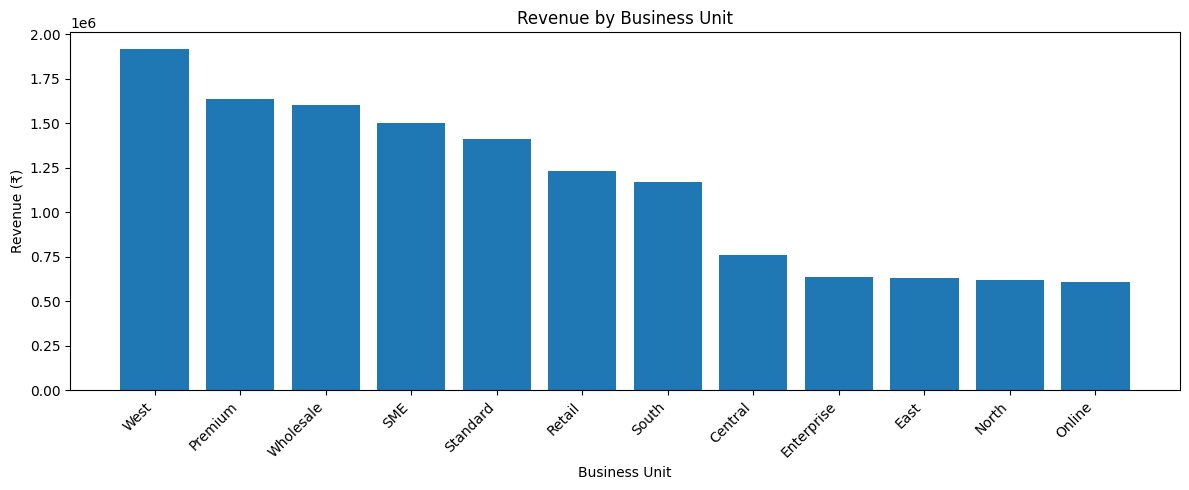

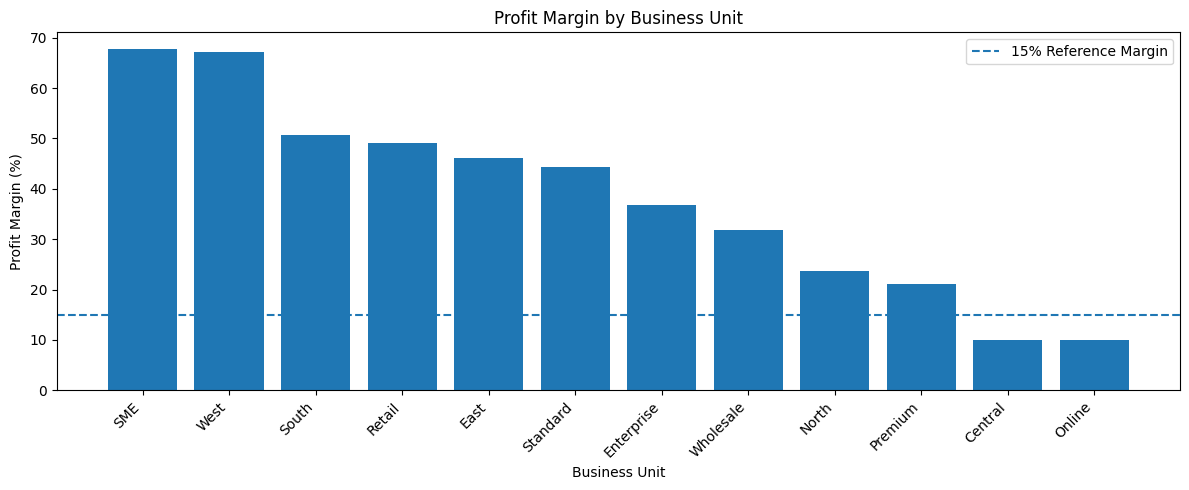

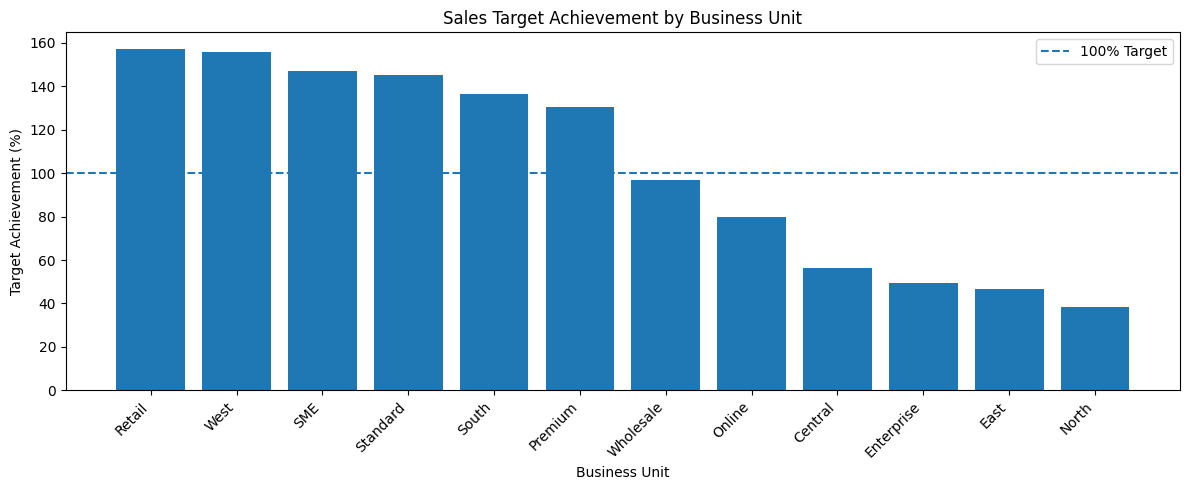

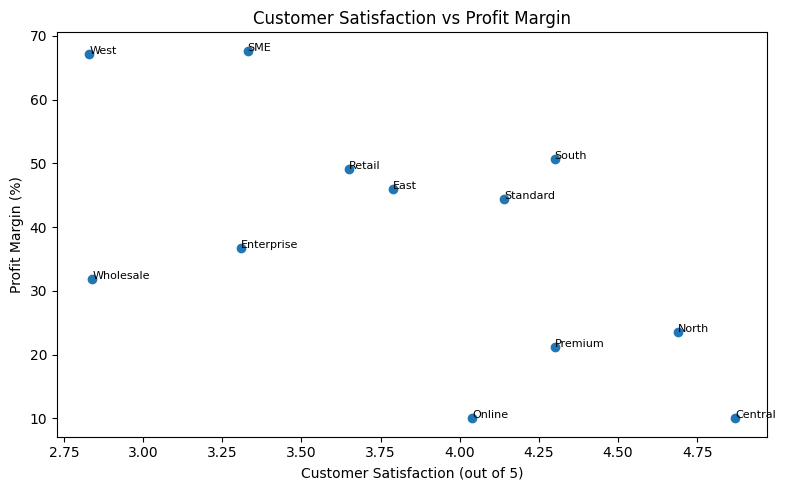


BUSINESS UNITS NEEDING ATTENTION
business_unit  revenue  profit  profit_margin_pct  target_achievement_pct                                                                       management_recommendation
       Online   610268   61027              10.00                   79.70 Review sales strategy and target gap; Investigate costs and pricing; Review delivery operations
      Central   759178   75918              10.00                   56.31                             Review sales strategy and target gap; Investigate costs and pricing
        North   621958  146755              23.60                   38.46                                                            Review sales strategy and target gap
   Enterprise   637337  233982              36.71                   49.34   Review sales strategy and target gap; Improve customer experience; Review delivery operations
         East   631932  290842              46.02                   46.64                                Review sale

In [1]:

# PROJECT 12: EXECUTIVE DECISION INTELLIGENCE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------
# 1. GENERATE SAMPLE BUSINESS DATA
# --------------------------------------------------

np.random.seed(42)

n = 12

df = pd.DataFrame({
    "business_unit": [
        "North", "South", "East", "West",
        "Central", "Online", "Retail", "Wholesale",
        "Enterprise", "SME", "Premium", "Standard"
    ],
    "revenue": np.random.randint(500000, 2000000, n),
    "cost": np.random.randint(300000, 1500000, n),
    "sales_target": np.random.randint(700000, 1800000, n),
    "customer_satisfaction": np.random.uniform(2.8, 5.0, n).round(2),
    "on_time_delivery_pct": np.random.uniform(70, 100, n).round(2),
    "employee_count": np.random.randint(10, 100, n)
})

# Ensure cost is below revenue in this illustrative dataset
df["cost"] = np.minimum(
    df["cost"],
    (df["revenue"] * 0.90).astype(int)
)

# --------------------------------------------------
# 2. CALCULATE EXECUTIVE KPIs
# --------------------------------------------------

df["profit"] = df["revenue"] - df["cost"]

df["profit_margin_pct"] = (
    df["profit"] / df["revenue"] * 100
).round(2)

df["target_achievement_pct"] = (
    df["revenue"] / df["sales_target"] * 100
).round(2)

df["revenue_per_employee"] = (
    df["revenue"] / df["employee_count"]
).round(2)

df["cost_to_revenue_pct"] = (
    df["cost"] / df["revenue"] * 100
).round(2)

# --------------------------------------------------
# 3. CLASSIFY BUSINESS PERFORMANCE
# --------------------------------------------------

def performance_status(row):
    if (
        row["target_achievement_pct"] >= 100
        and row["profit_margin_pct"] >= 20
    ):
        return "Strong"
    elif (
        row["target_achievement_pct"] < 80
        or row["profit_margin_pct"] < 10
    ):
        return "Needs Attention"
    return "Moderate"

df["performance_status"] = df.apply(
    performance_status, axis=1
)

# --------------------------------------------------
# 4. GENERATE MANAGEMENT RECOMMENDATIONS
# --------------------------------------------------

def recommendation(row):
    actions = []

    if row["target_achievement_pct"] < 100:
        actions.append("Review sales strategy and target gap")

    if row["profit_margin_pct"] < 15:
        actions.append("Investigate costs and pricing")

    if row["customer_satisfaction"] < 3.5:
        actions.append("Improve customer experience")

    if row["on_time_delivery_pct"] < 85:
        actions.append("Review delivery operations")

    if not actions:
        actions.append("Maintain performance and share best practices")

    return "; ".join(actions)

df["management_recommendation"] = df.apply(
    recommendation, axis=1
)

# --------------------------------------------------
# 5. EXECUTIVE SUMMARY
# --------------------------------------------------

total_revenue = df["revenue"].sum()
total_cost = df["cost"].sum()
total_profit = df["profit"].sum()

overall_profit_margin = (
    total_profit / total_revenue * 100
)

overall_target_achievement = (
    total_revenue / df["sales_target"].sum() * 100
)

average_customer_satisfaction = (
    df["customer_satisfaction"].mean()
)

average_on_time_delivery = (
    df["on_time_delivery_pct"].mean()
)

print("=" * 55)
print("EXECUTIVE DECISION INTELLIGENCE DASHBOARD")
print("=" * 55)

print(f"Total Revenue: ₹{total_revenue:,.0f}")
print(f"Total Cost: ₹{total_cost:,.0f}")
print(f"Total Profit: ₹{total_profit:,.0f}")
print(f"Overall Profit Margin: {overall_profit_margin:.2f}%")
print(f"Sales Target Achievement: {overall_target_achievement:.2f}%")
print(f"Average Customer Satisfaction: {average_customer_satisfaction:.2f}/5")
print(f"Average On-Time Delivery: {average_on_time_delivery:.2f}%")

# --------------------------------------------------
# 6. BUSINESS UNIT PERFORMANCE TABLE
# --------------------------------------------------

columns_to_display = [
    "business_unit",
    "revenue",
    "profit",
    "profit_margin_pct",
    "target_achievement_pct",
    "customer_satisfaction",
    "on_time_delivery_pct",
    "performance_status"
]

print("\nBUSINESS UNIT PERFORMANCE")
print(
    df[columns_to_display]
    .sort_values("profit", ascending=False)
    .round(2)
    .to_string(index=False)
)

# --------------------------------------------------
# 7. CHART: REVENUE BY BUSINESS UNIT
# --------------------------------------------------

revenue_sorted = df.sort_values("revenue", ascending=False)

plt.figure(figsize=(12, 5))
plt.bar(
    revenue_sorted["business_unit"],
    revenue_sorted["revenue"]
)
plt.title("Revenue by Business Unit")
plt.xlabel("Business Unit")
plt.ylabel("Revenue (₹)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 8. CHART: PROFIT MARGIN BY BUSINESS UNIT
# --------------------------------------------------

margin_sorted = df.sort_values(
    "profit_margin_pct", ascending=False
)

plt.figure(figsize=(12, 5))
plt.bar(
    margin_sorted["business_unit"],
    margin_sorted["profit_margin_pct"]
)
plt.axhline(
    15,
    linestyle="--",
    label="15% Reference Margin"
)
plt.title("Profit Margin by Business Unit")
plt.xlabel("Business Unit")
plt.ylabel("Profit Margin (%)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 9. CHART: SALES TARGET ACHIEVEMENT
# --------------------------------------------------

target_sorted = df.sort_values(
    "target_achievement_pct", ascending=False
)

plt.figure(figsize=(12, 5))
plt.bar(
    target_sorted["business_unit"],
    target_sorted["target_achievement_pct"]
)
plt.axhline(
    100,
    linestyle="--",
    label="100% Target"
)
plt.title("Sales Target Achievement by Business Unit")
plt.xlabel("Business Unit")
plt.ylabel("Target Achievement (%)")
plt.xticks(rotation=45, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

# --------------------------------------------------
# 10. CHART: CUSTOMER SATISFACTION VS PROFIT MARGIN
# --------------------------------------------------

plt.figure(figsize=(8, 5))
plt.scatter(
    df["customer_satisfaction"],
    df["profit_margin_pct"]
)
plt.title("Customer Satisfaction vs Profit Margin")
plt.xlabel("Customer Satisfaction (out of 5)")
plt.ylabel("Profit Margin (%)")

for _, row in df.iterrows():
    plt.annotate(
        row["business_unit"],
        (
            row["customer_satisfaction"],
            row["profit_margin_pct"]
        ),
        fontsize=8
    )

plt.tight_layout()
plt.show()

# --------------------------------------------------
# 11. MANAGEMENT PRIORITY LIST
# --------------------------------------------------

priority_units = df[
    df["performance_status"] == "Needs Attention"
].sort_values("profit_margin_pct")

print("\nBUSINESS UNITS NEEDING ATTENTION")

if priority_units.empty:
    print("No units meet the defined attention criteria.")
else:
    print(
        priority_units[
            [
                "business_unit",
                "revenue",
                "profit",
                "profit_margin_pct",
                "target_achievement_pct",
                "management_recommendation"
            ]
        ].round(2).to_string(index=False)
    )

# --------------------------------------------------
# 12. RECOMMENDATIONS FOR EXECUTIVES
# --------------------------------------------------

print("\nEXECUTIVE RECOMMENDATIONS")

below_target = df[
    df["target_achievement_pct"] < 100
]["business_unit"].tolist()

low_margin = df[
    df["profit_margin_pct"] < 15
]["business_unit"].tolist()

low_satisfaction = df[
    df["customer_satisfaction"] < 3.5
]["business_unit"].tolist()

low_delivery = df[
    df["on_time_delivery_pct"] < 85
]["business_unit"].tolist()

if below_target:
    print("1. Review sales gaps in:", ", ".join(below_target))
else:
    print("1. All business units achieved their sales targets.")

if low_margin:
    print("2. Investigate cost and pricing in:", ", ".join(low_margin))
else:
    print("2. No business units have profit margins below 15%.")

if low_satisfaction:
    print("3. Review customer feedback in:", ", ".join(low_satisfaction))
else:
    print("3. Customer satisfaction meets the defined threshold.")

if low_delivery:
    print("4. Review delivery processes in:", ", ".join(low_delivery))
else:
    print("4. Delivery performance meets the defined threshold.")

best_unit = df.loc[df["profit"].idxmax(), "business_unit"]
print("5. Review best practices from the highest-profit unit:", best_unit)

# --------------------------------------------------
# 13. EXPORT RESULTS
# --------------------------------------------------

output_file = "executive_decision_intelligence_results.csv"
df.to_csv(output_file, index=False)

print("\nDetailed results saved to:", output_file)
print("\nNOTE: All data is synthetic and for educational use only.")
